# Limpeza de Dados em R

Bibliotecas úteis

In [1]:
library(repr)

Prepraração do ambiente: 

In [4]:
# Ajusta Jupyter para que gráficos sejam 11 x 5
options(repr.plot.width=11,repr.plot.height=5)

## Carga

### Obtenção dos dados

In [5]:
# eliminar todas variáveis definidas até aqui
rm(list=ls())

O comando `read.table` é o comando genérico para leitura de dados na forma de tabela de dados. Há uma forma mais pré-configurada para ler arquivos texto separados por vírgula (ou _comma separated values_ - CSV - como é conhecido). O comando é `read.csv`.

- ler os dados de `arquivo.csv`; 
- o nome das variáveis está na primeira linha `header=TRUE`;
- o separador entre os valores é a `,` (`sep=","`).

É possível ler já descompactando de um arquivo compactado (zip, gz etc) informando qual é o arquivo dentro do arquivo .zip. 

In [19]:
# ler dados de um arquivo compactado, com valores separados por ";", 
# sem nome das variáveis na primeira linha
cepagri_00 <- read.csv(unzip("cepagri_2017_2022.zip","cepagri_2017_2022.csv"),
                       sep=";", header=FALSE)

Os dados:

In [20]:
head(cepagri_00,10)
tail(cepagri_00,10)

,V1,V2,V3,V4,V5
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
1,01/01/2017-00:00,22.2,16.2,83.9,21.1
2,01/01/2017-00:10,[ERRO],NA,NA,NA
3,01/01/2017-00:20,[ERRO],NA,NA,NA
4,01/01/2017-00:30,[ERRO],NA,NA,NA
5,01/01/2017-00:40,[ERRO],NA,NA,NA
6,01/01/2017-00:50,[ERRO],NA,NA,NA
7,01/01/2017-01:00,[ERRO],NA,NA,NA
8,01/01/2017-01:10,[ERRO],NA,NA,NA
9,01/01/2017-01:20,21.7,4.0,84.7,20.6


,V1,V2,V3,V4,V5
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
282365,07/06/2022-08:00,15.8,6.4,81.5,14.0
282366,07/06/2022-08:10,16.7,3.9,79.9,15.1
282367,07/06/2022-08:20,17.5,5.0,77.5,16.0
282368,07/06/2022-08:30,17.9,6.0,75.5,16.5
282369,07/06/2022-08:40,18.3,6.7,74.5,16.9
282370,07/06/2022-08:50,18.7,6.5,74.3,17.3
282371,07/06/2022-09:00,19.3,5.5,73.2,17.9
282372,07/06/2022-09:10,19.2,5.6,73.1,17.8
282373,07/06/2022-09:20,19.6,5.2,73.2,18.3


As variáveis `V1` a `V5` são, respectivamento o **marco temporal** (_timestamp_) em que ocorreu a medida (variável `horario`), a **temperatura** medida em °C (`temp`), a **velocidade do vento** em km/h (`vento`), a **umidade** do ar em % (`umid`) e a **sensação térmica** em °C (`sensacao`).

In [21]:
names(cepagri_00) <- c("horario","temp","vento","umid","sensacao")

Estrutura do `data frame`  que contém os dados:

In [22]:
str(cepagri_00)

'data.frame':	282374 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-00:10" "01/01/2017-00:20" "01/01/2017-00:30" ...
 $ temp    : chr  "22.2" " [ERRO]" " [ERRO]" " [ERRO]" ...
 $ vento   : num  16.2 NA NA NA NA NA NA NA 4 9.2 ...
 $ umid    : num  83.9 NA NA NA NA NA NA NA 84.7 87.6 ...
 $ sensacao: num  21.1 NA NA NA NA NA NA NA 20.6 20.3 ...


In [23]:
# arquivo original em formato R: compacto e eficiente para carregar
save(cepagri_00, file="cepagri_00.RData")

In [24]:
# qualquer problema, pode-se retomar o trabalho daqui descomentando o load:
# load("cepagri_00.RData")

In [25]:
# usando df (data frame) para ficar mais fácil de escrever que cepagri_00
df <- cepagri_00
# liberando o cepagri_00 da memória
rm(cepagri_00)

### Temperatura como caractere

In [26]:
# Por quê a temperatura foi importada como texto? 
# achar os registros de temperatura que têm caracteres:
linhas <- grep("[A-Za-z]", df$temp)
head(linhas,10)
tail(linhas,10)

[1]    2    3    4    5    6    7    8 1830 1831 1832

[1] 281928 282030 282071 282072 282215 282216 282264 282318 282359 282360

In [27]:
head(df[linhas,],10)

,horario,temp,vento,umid,sensacao
,<chr>,<chr>,<dbl>,<dbl>,<dbl>
2,01/01/2017-00:10,[ERRO],NA,NA,NA
3,01/01/2017-00:20,[ERRO],NA,NA,NA
4,01/01/2017-00:30,[ERRO],NA,NA,NA
5,01/01/2017-00:40,[ERRO],NA,NA,NA
6,01/01/2017-00:50,[ERRO],NA,NA,NA
7,01/01/2017-01:00,[ERRO],NA,NA,NA
8,01/01/2017-01:10,[ERRO],NA,NA,NA
1830,14/01/2017-23:10,[ERRO],NA,NA,NA
1831,14/01/2017-23:20,[ERRO],NA,NA,NA


Ops, tem valores de temperatura registradas como "[ERRO]" e que causaram a perda dos valores das demais variáveis

In [28]:
# Excluindo as linhas com "[ERRO]" na temperatura de df
df <- df[-linhas,]

In [29]:
str(df)

'data.frame':	248008 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-01:20" "01/01/2017-01:30" "01/01/2017-01:40" ...
 $ temp    : chr  "22.2" "21.7" "21.5" "21.6" ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...


Dispensadas 34366 linhas com problemas. Ainda há texto em `temp`?

In [30]:
linhas <- grep("[A-Za-z]", df$temp)
linhas
length(linhas)

integer(0)

[1] 0

Não há mais texto, então pode ser convertida para número:

In [31]:
df$temp <- as.numeric(df$temp)

Como está a estrutura do `data frame`

In [32]:
str(df)

'data.frame':	248008 obs. of  5 variables:
 $ horario : chr  "01/01/2017-00:00" "01/01/2017-01:20" "01/01/2017-01:30" "01/01/2017-01:40" ...
 $ temp    : num  22.2 21.7 21.5 21.6 21.2 21.3 21.5 21.7 22 22 ...
 $ vento   : num  16.2 4 9.2 7.8 11.6 0.5 4 5.4 0 0 ...
 $ umid    : num  83.9 84.7 87.6 86.4 87.7 87.4 85.3 83.6 82.2 82.3 ...
 $ sensacao: num  21.1 20.6 20.3 20.4 20.1 20.2 20.3 20.6 20.9 20.9 ...


Aparentemente, ok.   
Mas será?

In [33]:
summary(df)

   horario               temp           vento             umid       
 Length:248008      Min.   : 4.60   Min.   :  0.00   Min.   :  0.00  
 Class :character   1st Qu.:18.90   1st Qu.: 10.70   1st Qu.: 55.10  
 Mode  :character   Median :21.70   Median : 19.30   Median : 71.10  
                    Mean   :22.22   Mean   : 23.01   Mean   : 67.29  
                    3rd Qu.:25.80   3rd Qu.: 32.20   3rd Qu.: 81.60  
                    Max.   :37.40   Max.   :120.10   Max.   :100.00  
    sensacao    
 Min.   :-0.20  
 1st Qu.:17.50  
 Median :20.50  
 Mean   :20.84  
 3rd Qu.:24.60  
 Max.   :99.90  

#### Temperatura

Entre 4,6°C e 37,4°C, com média em 22,2°C. Parece Campinas...

In [34]:
# preparação para ajustar a proporção dos gráficos
library(repr)
options(repr.plot.width=10, repr.plot.height=6)

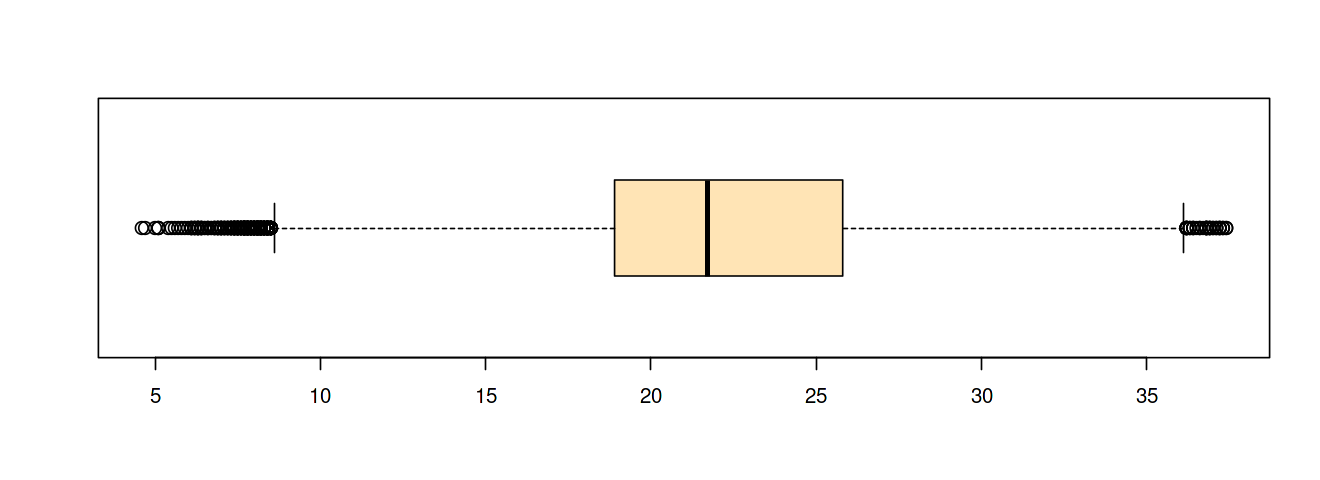

In [47]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$temp, horizontal=TRUE, cex=1.3, col="moccasin")

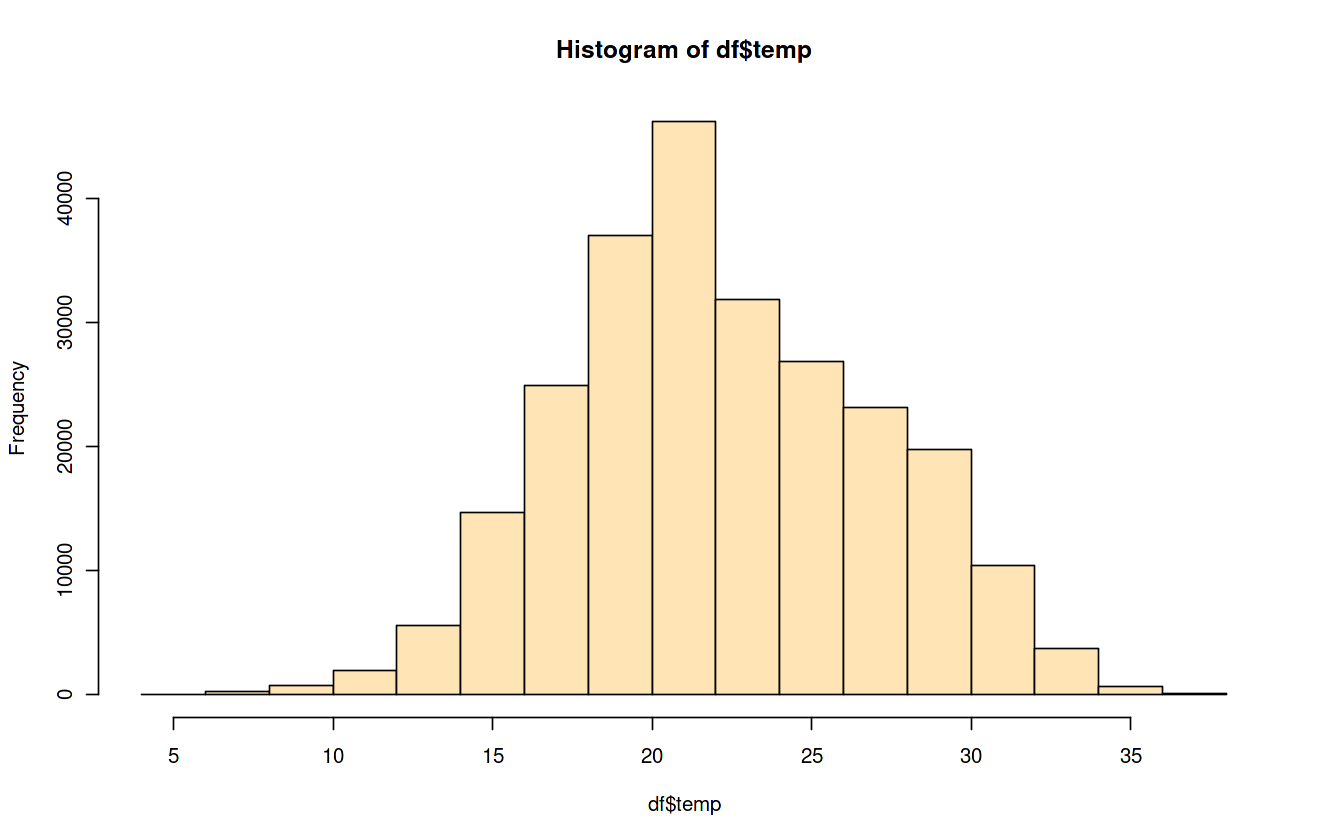

In [50]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$temp, col="moccasin")

#### Velocidade do vento

Mínimo em 0 km/h e máximo em 120 km/h. **Ops**.

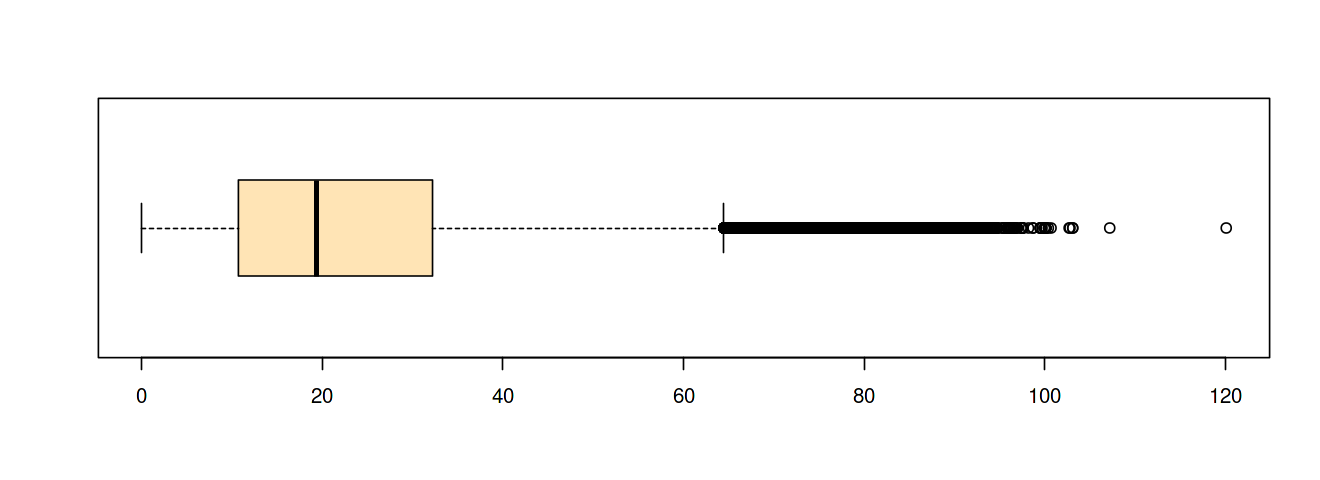

In [48]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$vento, horizontal=TRUE, col="moccasin")

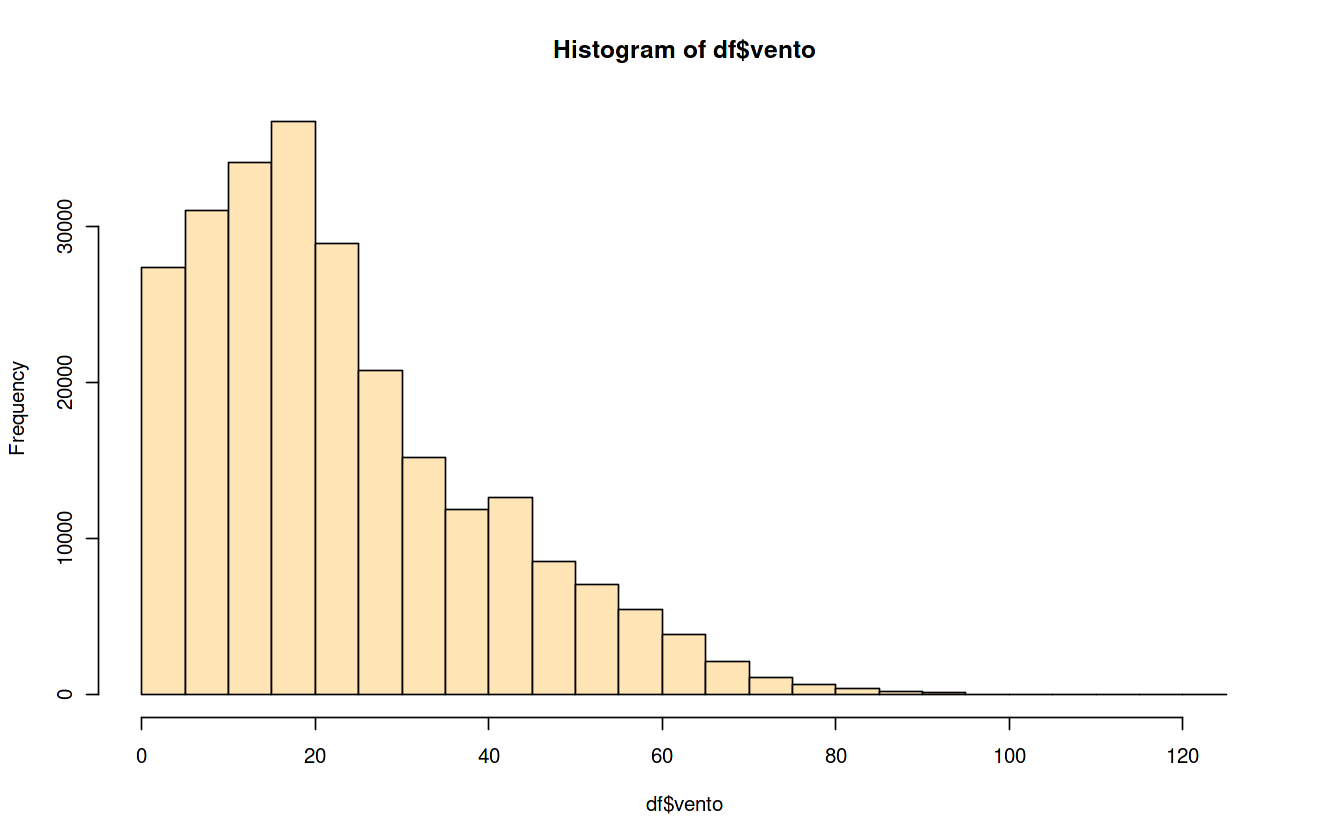

In [51]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$vento, col="moccasin")

In [52]:
# quais registros com vento acima de 100 km/h?
df[df$vento > 100,]

,horario,temp,vento,umid,sensacao
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
121085,28/04/2019-18:20,20.9,107.2,81.4,19.7
134873,02/08/2019-20:00,19.1,100.1,78.3,17.8
136575,14/08/2019-15:40,17.1,100.1,66.8,15.5
136576,14/08/2019-15:50,17.1,100.1,66.8,15.5
136577,14/08/2019-16:00,17.1,100.1,66.8,15.5
136578,14/08/2019-16:10,17.1,100.1,66.8,15.5
136579,14/08/2019-16:20,17.1,100.1,66.8,15.5
139745,05/09/2019-16:30,18.3,100.1,72.3,16.8
139746,05/09/2019-16:40,18.3,100.1,72.3,16.8


Todos os dias foram em 2019. O que teria acontecido entre abril e outubro de 2019?   
Pesquisar o que houve nesses dias, pois ventos de mais de 100 km/h causam grande destruição e, a partir 118 km/h já é considerado furacão.   
A propósito, nunca houve furacão em Campinas...

#### Umidade do ar

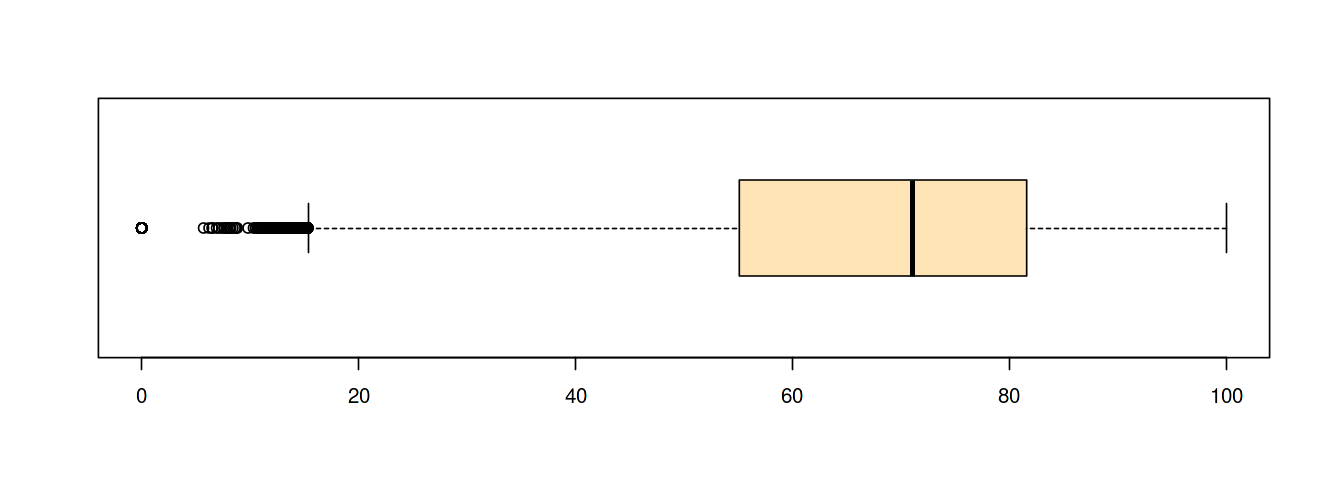

In [54]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$umid, horizontal=TRUE, col="moccasin")

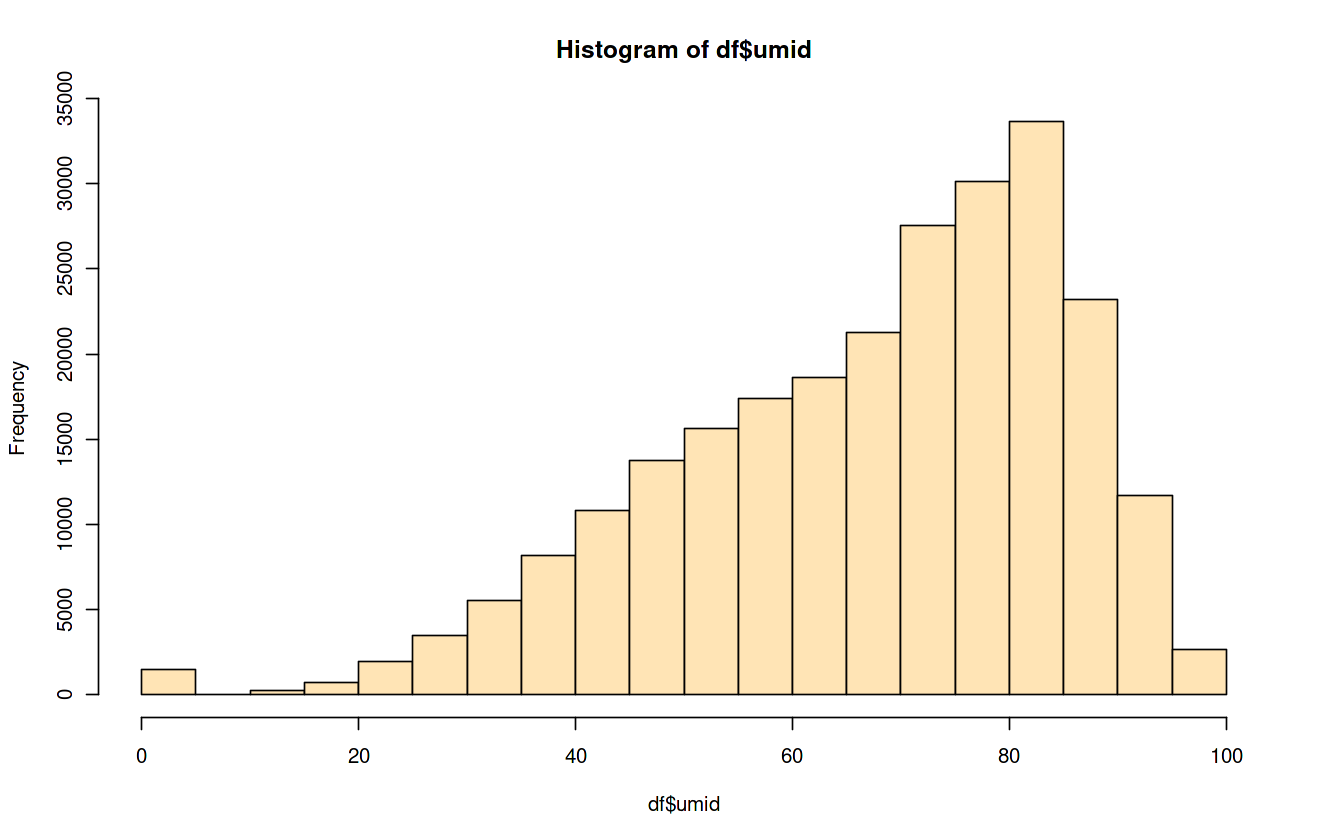

In [55]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$umid, col="moccasin")

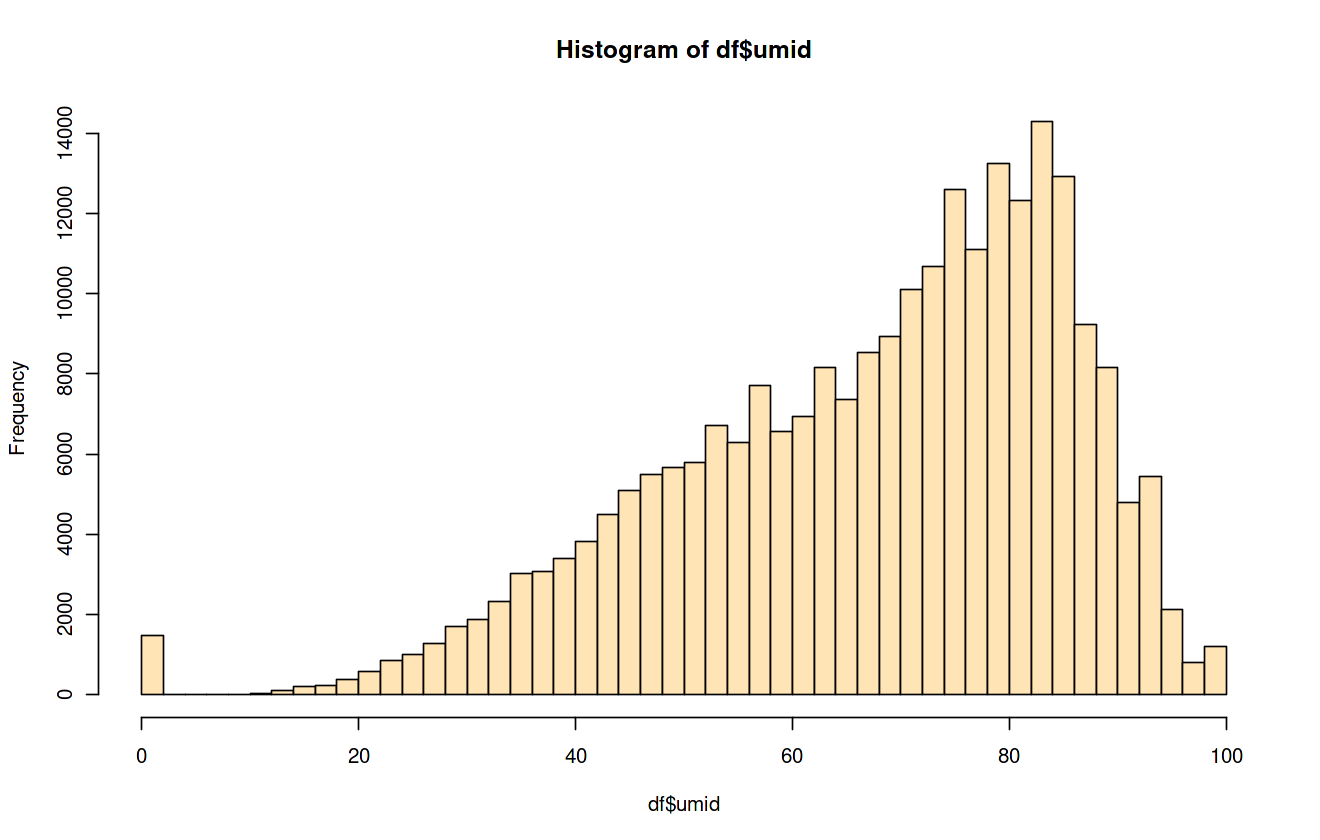

In [56]:
hist(df$umid, breaks=60, col="moccasin")

Tem uma grande quantidade de registros (aparentemente uns 1700) registrando 0% de umidade.   
É um problema, com certeza, pois _desertos_ tem em torno de 10% de umidade...

In [57]:
df[df$umid == 0, ]

,horario,temp,vento,umid,sensacao
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
104918,05/01/2019-07:00,20.6,17.0,0,19.4
104919,05/01/2019-07:10,20.6,15.7,0,19.5
104920,05/01/2019-07:20,20.6,15.7,0,19.5
104921,05/01/2019-07:30,20.7,14.7,0,19.6
104922,05/01/2019-07:40,20.8,15.2,0,19.6
104923,05/01/2019-07:50,20.8,15.2,0,19.6
104924,05/01/2019-08:00,20.9,15.2,0,19.7
104925,05/01/2019-08:10,20.8,18.6,0,19.7
105062,06/01/2019-07:00,20.4,13.8,0,19.2


Pois é, 2019 **e** 2020. 

Como se comportaram as medidas abaixo de 20% de umidade?

há 2386 registros abaixo de 20% de umidade

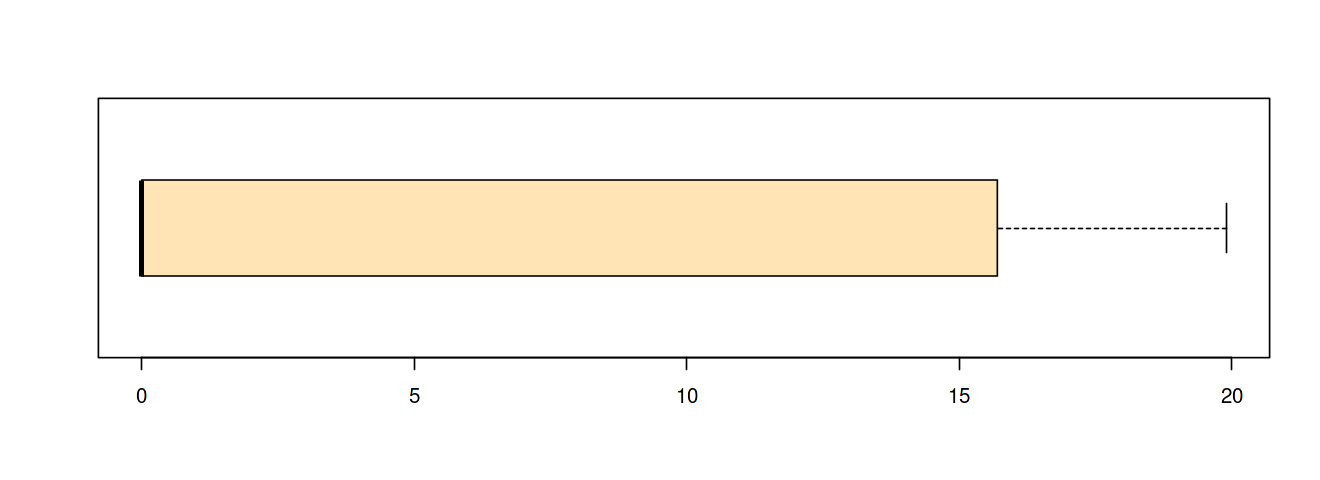

In [58]:
cat("há",length(df$umid[df$umid < 20]),"registros abaixo de 20% de umidade")
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$umid[df$umid < 20], horizontal=TRUE, col="moccasin")

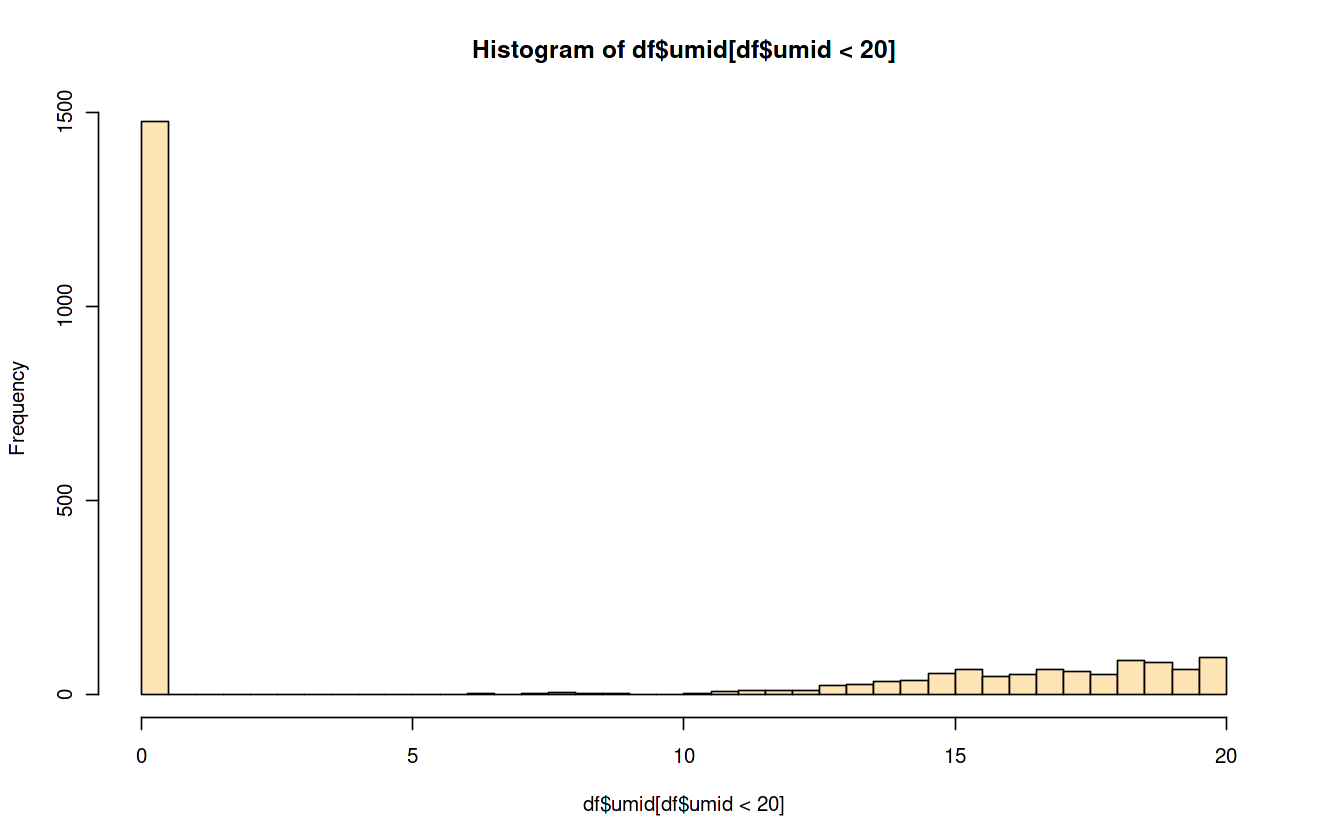

In [59]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$umid[df$umid < 20], breaks=30, col="moccasin")

Registros em torno de 10% são ruins, aparentemente são raros e devem ser estudados.   
Observações com 0% são seguramente erros e convém que sejam eliminados.

In [60]:
linhas <- df$umid != 0
linhas

[1] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [15] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [29] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [43] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [57] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [71] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [85] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
   [99] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [113] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [127] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [141] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [155] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [169] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [183] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [197] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [211] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [225] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [239] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [253] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [267] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [281] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [295] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [309] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [323] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [337] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [351] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [365] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [379] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [393] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [407] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [421] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [435] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [449] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [463] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [477] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [491] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [505] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [519] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [533] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [547] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [561] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [575] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [589] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [603] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [617] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [631] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [645] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [659] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [673] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [687] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [701] TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE TRUE
  [715] TRUE TRUE TRUE TRU

In [61]:
df <- df[linhas,]

In [62]:
summary(df)

   horario               temp           vento             umid       
 Length:246532      Min.   : 4.60   Min.   :  0.00   Min.   :  5.70  
 Class :character   1st Qu.:18.90   1st Qu.: 10.60   1st Qu.: 55.50  
 Mode  :character   Median :21.70   Median : 19.30   Median : 71.10  
                    Mean   :22.23   Mean   : 22.98   Mean   : 67.69  
                    3rd Qu.:25.80   3rd Qu.: 32.20   3rd Qu.: 81.60  
                    Max.   :37.40   Max.   :120.10   Max.   :100.00  
    sensacao    
 Min.   :-0.20  
 1st Qu.:17.60  
 Median :20.60  
 Mean   :20.85  
 3rd Qu.:24.60  
 Max.   :99.90  

#### Sensação térmica

Algo estranho nos valores da sensação térmica (`sensacao`)?   
Quantas vezes você ouviu "Está quente! A sensação térmica de hoje é 100°C" ...

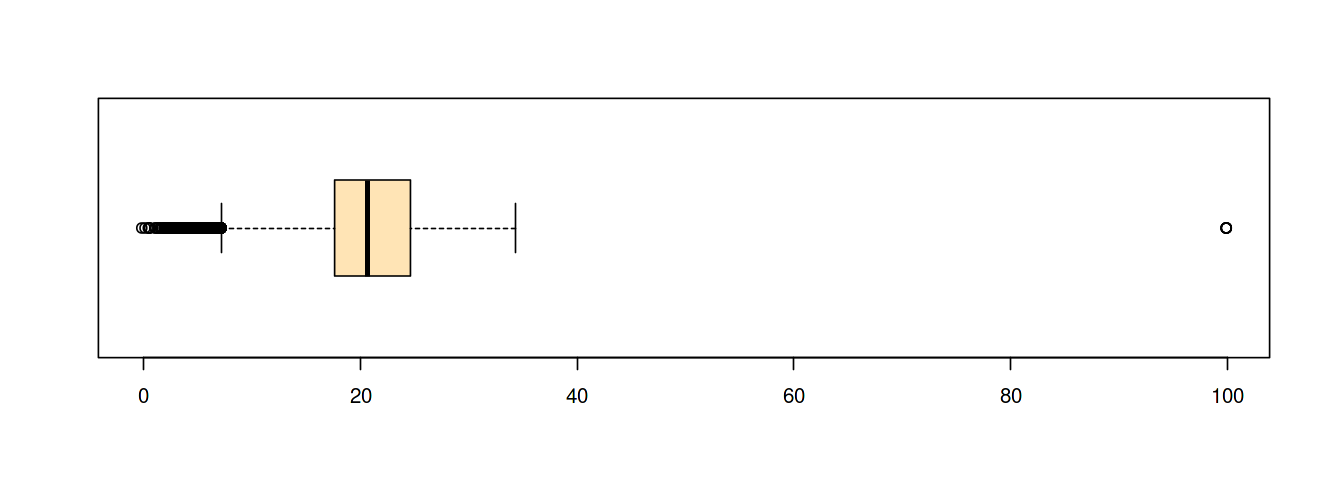

In [63]:
options(repr.plot.width=11,repr.plot.height=4)
boxplot(df$sensacao, horizontal=TRUE, col="moccasin")

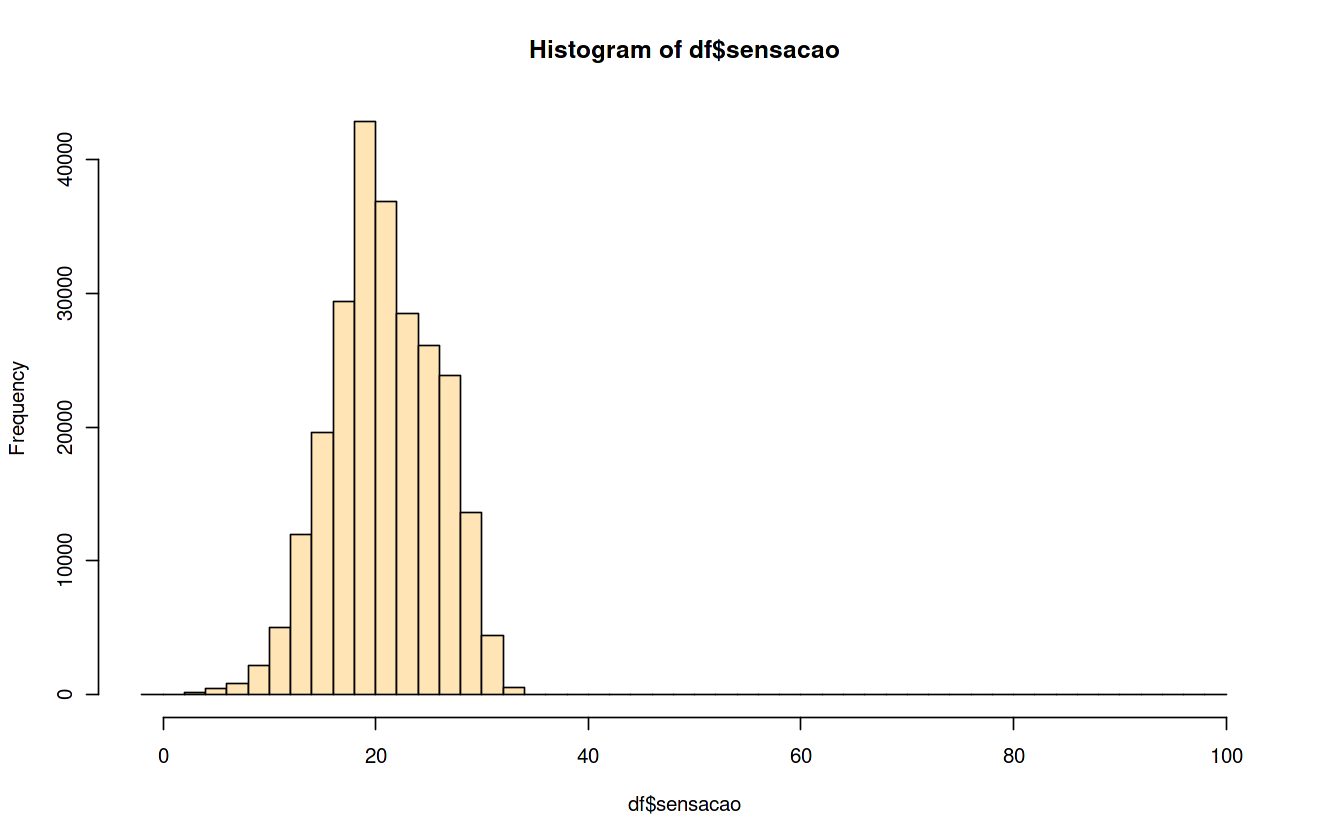

In [64]:
options(repr.plot.width=11,repr.plot.height=7)
hist(df$sensacao, breaks=50, col="moccasin")

A distribuição dos valores, diferentemente do caso da umidade, não são contínuos até 100°C. Aparentemente os casos com 100°C são isolados.

In [133]:
df[df$sensacao > 40,]

,horario,temp,vento,umid,sensacao
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
87668,07/09/2018-07:10,13.4,37.0,75.3,99.9
87812,08/09/2018-07:10,16.1,26.3,64.5,99.9
87956,09/09/2018-07:10,15.1,28.1,75.8,99.9
88100,10/09/2018-07:10,14.8,33.4,74.5,99.9
88244,11/09/2018-07:10,15.4,34.7,76.2,99.9


Interessante. Há cinco registros com sensação térmica de 99,9°C: são as medidas das 7h10 de 7 a 11 de setembro de 2018. Cinco dias em seguida, no mesmo horário, sendo o primeiro um feriado...

Como estão as medidas _vizinhas_?

In [65]:
# quais índices das linhas com problemas?
linhas <- which(df$sensacao == 99.9)
linhas

[1] 86401 86545 86689 86833 86977

In [66]:
x <- linhas[1]
x
medidas <- df[(x-3):(x+3), "sensacao"]
medidas
media   <- mean(medidas[-4])
media
df[x, "sensacao"] <- media
df[x,]

[1] 86401

[1] 10.3 10.6 10.6 99.9 11.7 12.1 12.4

[1] 11.28333

,horario,temp,vento,umid,sensacao
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
87668,07/09/2018-07:10,13.4,37,75.3,11.28333


In [136]:
for (x in linhas) {
    medidas <- df[(x-3):(x+3), "sensacao"]
    media   <- mean(medidas[-4])
    df[x, "sensacao"] <- media
}

In [137]:
df[linhas,]

,horario,temp,vento,umid,sensacao
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
87668,07/09/2018-07:10,13.4,37.0,75.3,11.28333
87812,08/09/2018-07:10,16.1,26.3,64.5,14.58333
87956,09/09/2018-07:10,15.1,28.1,75.8,13.23333
88100,10/09/2018-07:10,14.8,33.4,74.5,12.95000
88244,11/09/2018-07:10,15.4,34.7,76.2,13.73333


In [ ]:
summary(df)

In [ ]:
cepagri_01 <- df

In [ ]:
save(cepagri_01, file="cepagri_01.RData")